In [1]:
# =============================================================================
# CELL 1: ENVIRONMENT SETUP & LIBRARY DEPENDENCIES
# =============================================================================
import os
import re
import string
import time
import warnings
warnings.filterwarnings('ignore')

# Core data manipulation and scientific computation libraries
import numpy as np
import pandas as pd

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn machine learning pipeline, modeling, and evaluation modules
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

# Configure visualization themes for clean, legible plots
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

print("Environment initialized and libraries imported successfully.")

Environment initialized and libraries imported successfully.


In [2]:
# =============================================================================
# CELL 2: DATA INGESTION & STRUCTURAL INSPECTION
# =============================================================================
DATA_PATH = 'bitext_customer_support_training_dataset.csv'

# Verify file presence or load from relative data directory
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join('data', 'bitext_customer_support_training_dataset.csv')

df = pd.read_csv(DATA_PATH)

print(f"Dataset successfully loaded. Total Records: {df.shape[0]:,}, Attributes: {df.shape[1]}")
print("\n--- Feature Data Types & Null Value Check ---")
print(df.info())

print("\n--- Explicit Missing Value Quantities per Attribute ---")
print(df.isnull().sum())

print("\n--- Sample Inbound Customer Support Utterances ---")
display(df.head(5))

Dataset successfully loaded. Total Records: 8,175, Attributes: 4

--- Feature Data Types & Null Value Check ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8175 entries, 0 to 8174
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   flags      8175 non-null   object
 1   utterance  8175 non-null   object
 2   category   8175 non-null   object
 3   intent     8175 non-null   object
dtypes: object(4)
memory usage: 255.6+ KB
None

--- Explicit Missing Value Quantities per Attribute ---
flags        0
utterance    0
category     0
intent       0
dtype: int64

--- Sample Inbound Customer Support Utterances ---


,flags,utterance,category,intent
0,BM,I have problems with canceling an order,ORDER,cancel_order
1,BIM,how can I find information about canceling ord...,ORDER,cancel_order
2,B,I need help with canceling the last order,ORDER,cancel_order
3,BIP,could you help me cancelling the last order I ...,ORDER,cancel_order
4,B,problem with cancelling an order I made,ORDER,cancel_order


In [3]:
# =============================================================================
# CELL 3: DEDUPLICATION & TEXT NORMALIZATION
# =============================================================================
initial_rows = len(df)

# 1. Deduplication Analysis
exact_dupes = df.duplicated().sum()
text_dupes = df.duplicated(subset=['utterance']).sum()
print(f"Initial Total Observations: {initial_rows}")
print(f"Full Record Exact Duplicates: {exact_dupes}")
print(f"Utterance Text Duplicate Matches: {text_dupes}")

if text_dupes > 0:
    df = df.drop_duplicates(subset=['utterance']).reset_index(drop=True)
    print(f"Post-deduplication Record Count: {len(df)}")
else:
    print("Dataset contains 100% unique utterance records. No deduplication pruning required.")

# 2. Text Normalization Pipeline Function
def normalize_transcript(text):
    """
    Normalizes raw customer transcript text through case folding, URL removal,
    punctuation stripping, and whitespace collapse.
    """
    if not isinstance(text, str):
        return ""
    # Case folding
    text = text.lower()
    # Remove web protocols / URLs
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    # Remove punctuation characters
    text = text.translate(str.maketrans('', '', string.punctuation))
    # Normalize multiple whitespace occurrences
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Apply normalization
df['cleaned_text'] = df['utterance'].apply(normalize_transcript)

# Remove empty residual strings
df = df[df['cleaned_text'].str.len() > 0].reset_index(drop=True)

print(f"Cleaned Dataset Dimensions: {df.shape}")
display(df[['utterance', 'cleaned_text', 'intent', 'category']].head(3))

Initial Total Observations: 8175
Full Record Exact Duplicates: 0
Utterance Text Duplicate Matches: 0
Dataset contains 100% unique utterance records. No deduplication pruning required.
Cleaned Dataset Dimensions: (8175, 5)


,utterance,cleaned_text,intent,category
0,I have problems with canceling an order,i have problems with canceling an order,cancel_order,ORDER
1,how can I find information about canceling ord...,how can i find information about canceling orders,cancel_order,ORDER
2,I need help with canceling the last order,i need help with canceling the last order,cancel_order,ORDER


In [4]:
# =============================================================================
# CELL 4: FEATURE ENGINEERING & IQR OUTLIER DETECTION
# =============================================================================
df['token_count'] = df['cleaned_text'].apply(lambda x: len(x.split()))
df['char_length'] = df['cleaned_text'].apply(len)
df['avg_word_length'] = df['char_length'] / df['token_count'].replace(0, 1)

print("--- Engineered Linguistic Feature Summary Statistics ---")
display(df[['token_count', 'char_length', 'avg_word_length']].describe().round(2))

# Statistical Outlier Detection using the IQR Method
Q1 = df['token_count'].quantile(0.25)
Q3 = df['token_count'].quantile(0.75)
IQR = Q3 - Q1
lower_fence = max(1.0, Q1 - 1.5 * IQR)
upper_fence = Q3 + 1.5 * IQR

length_outliers = df[(df['token_count'] < lower_fence) | (df['token_count'] > upper_fence)]
print(f"\nIQR Fence Bounds: Q1={Q1:.1f}, Q3={Q3:.1f}, IQR={IQR:.1f}")
print(f"Lower Outlier Fence: {lower_fence:.1f} tokens | Upper Outlier Fence: {upper_fence:.1f} tokens")
print(f"Identified Length Outlier Records: {len(length_outliers)} ({len(length_outliers)/len(df)*100:.2f}% of data)")

# Analytical Decision on Outliers:
print("\nDecision on Outliers:")
print("Inspecting short queries (e.g., 'cancel order', 2 tokens) confirms they represent legitimate,")
print("direct customer intents rather than corrupted data. Preserving all legitimate query lengths")
print("guarantees that the classifier generalizes across terse and verbose live chat inputs alike.")

--- Engineered Linguistic Feature Summary Statistics ---


,token_count,char_length,avg_word_length
count,8175.00,8175.00,8175.00
mean,8.32,42.17,5.20
std,2.38,10.52,0.93
min,1.00,6.00,3.33
25%,7.00,35.00,4.50
50%,8.00,43.00,5.09
75%,10.00,51.00,5.70
max,15.00,60.00,11.00



IQR Fence Bounds: Q1=7.0, Q3=10.0, IQR=3.0
Lower Outlier Fence: 2.5 tokens | Upper Outlier Fence: 14.5 tokens
Identified Length Outlier Records: 82 (1.00% of data)

Decision on Outliers:
Inspecting short queries (e.g., 'cancel order', 2 tokens) confirms they represent legitimate,
direct customer intents rather than corrupted data. Preserving all legitimate query lengths
guarantees that the classifier generalizes across terse and verbose live chat inputs alike.


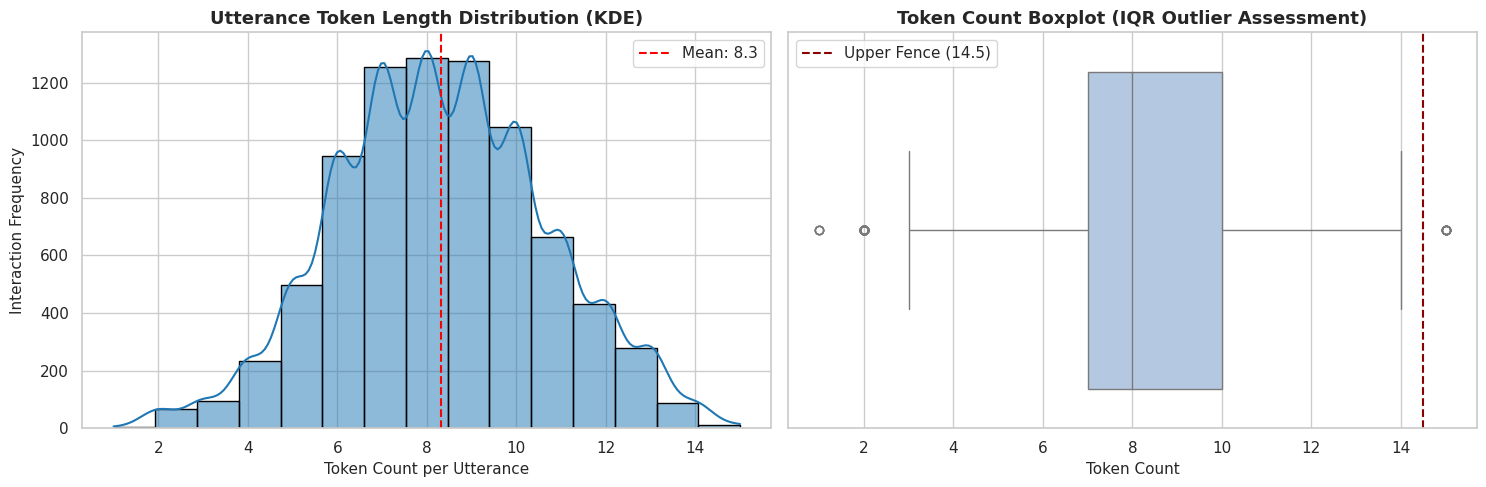

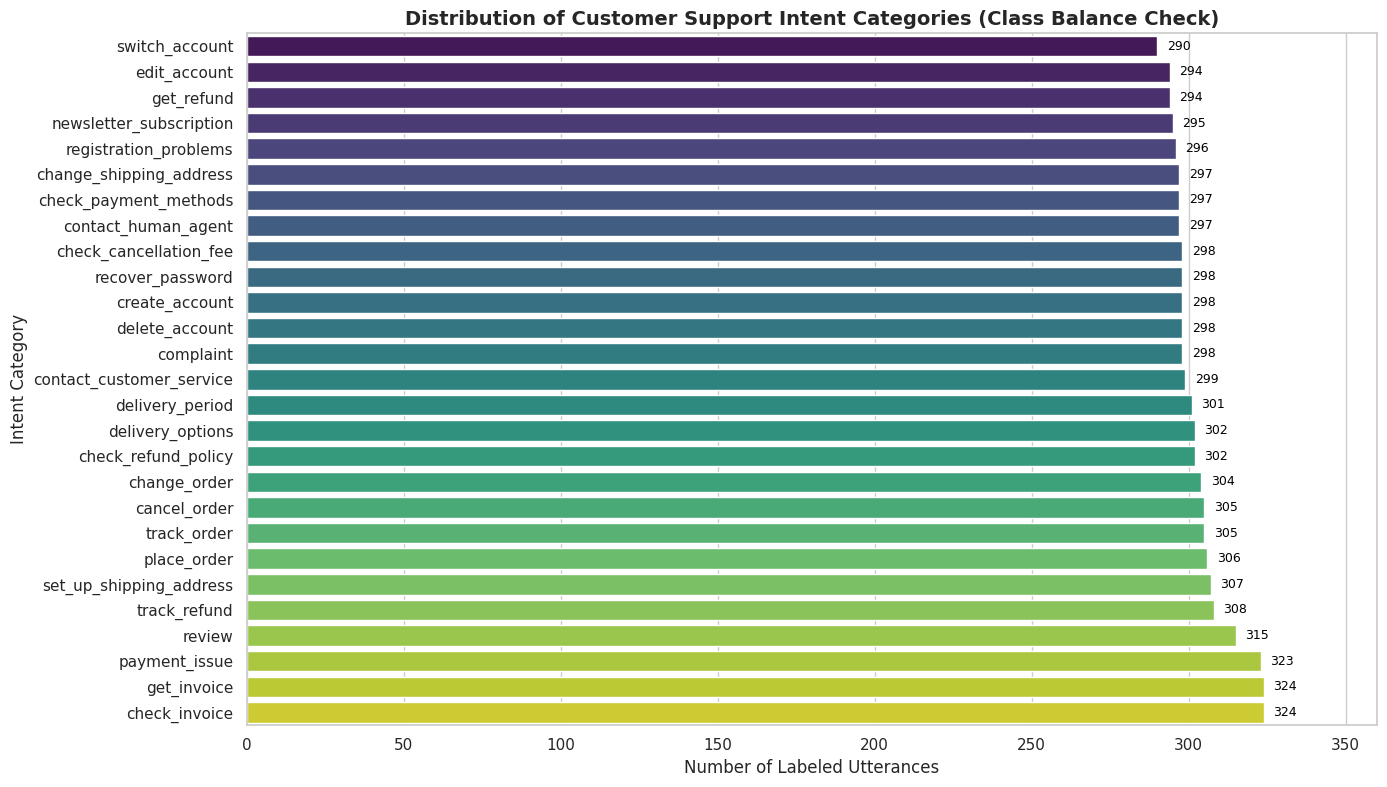

In [5]:
# =============================================================================
# CELL 5: VISUALIZATIONS (DISTRIBUTIONS, OUTLIERS & CLASS BALANCE)
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Subplot 1: Utterance Token Count Distribution
sns.histplot(df['token_count'], bins=15, kde=True, ax=axes[0], color='#1f77b4', edgecolor='black')
axes[0].set_title('Utterance Token Length Distribution (KDE)', fontweight='bold')
axes[0].set_xlabel('Token Count per Utterance')
axes[0].set_ylabel('Interaction Frequency')
axes[0].axvline(df['token_count'].mean(), color='red', linestyle='--', label=f"Mean: {df['token_count'].mean():.1f}")
axes[0].legend()

# Subplot 2: Token Count Box Plot for Outlier Inspection
sns.boxplot(x=df['token_count'], ax=axes[1], color='#aec7e8')
axes[1].axvline(upper_fence, color='darkred', linestyle='--', label=f'Upper Fence ({upper_fence:.1f})')
axes[1].set_title('Token Count Boxplot (IQR Outlier Assessment)', fontweight='bold')
axes[1].set_xlabel('Token Count')
axes[1].legend()

plt.tight_layout()
plt.show()

# Target Class Balance Distribution Plot
plt.figure(figsize=(14, 8))
intent_dist = df['intent'].value_counts().sort_values(ascending=True)
sns.barplot(x=intent_dist.values, y=intent_dist.index, palette='viridis')
plt.title('Distribution of Customer Support Intent Categories (Class Balance Check)', fontsize=14, fontweight='bold')
plt.xlabel('Number of Labeled Utterances', fontsize=12)
plt.ylabel('Intent Category', fontsize=12)
plt.xlim(0, 360)
for i, v in enumerate(intent_dist.values):
    plt.text(v + 3, i, str(v), color='black', va='center', fontsize=9)
plt.tight_layout()
plt.show()

In [6]:
# =============================================================================
# CELL 6: DATA PARTITIONING & TF-IDF FEATURE EXTRACTION
# =============================================================================
X = df['cleaned_text']
y = df['intent']

# Stratified 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training Partition: {X_train.shape[0]:,} samples")
print(f"Held-Out Testing Partition: {X_test.shape[0]:,} samples")

# Configure TF-IDF Vectorizer
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

# Fit on training data and transform both partitions
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print(f"Extracted Vocabulary Size: {X_train_vec.shape[1]:,} features")
print(f"Training Vector Matrix Shape: {X_train_vec.shape}")
print(f"Testing Vector Matrix Shape: {X_test_vec.shape}")

Training Partition: 6,540 samples
Held-Out Testing Partition: 1,635 samples
Extracted Vocabulary Size: 1,869 features
Training Vector Matrix Shape: (6540, 1869)
Testing Vector Matrix Shape: (1635, 1869)


In [7]:
# =============================================================================
# CELL 7: CROSS-VALIDATION ACROSS MULTIPLE ALGORITHMS
# =============================================================================
candidate_models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Random Forest (100 Trees)": RandomForestClassifier(n_estimators=100, random_state=42),
    "Logistic Regression (C=1.0)": LogisticRegression(max_iter=1000, C=1.0, random_state=42),
    "Linear Support Vector Classifier": LinearSVC(C=1.0, random_state=42, dual=False)
}

cv_summary = []
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("--- Executing 5-Fold Stratified Cross-Validation on Training Set ---")
for model_name, model in candidate_models.items():
    start_time = time.time()
    scores = cross_val_score(model, X_train_vec, y_train, cv=skf, scoring='f1_macro', n_jobs=-1)
    elapsed = time.time() - start_time
    cv_summary.append({
        "Model": model_name,
        "5-Fold CV Macro F1 (Mean)": scores.mean(),
        "5-Fold CV Macro F1 (Std Dev)": scores.std(),
        "CV Execution Time (s)": round(elapsed, 2)
    })
    print(f"{model_name:<36} | Mean Macro F1: {scores.mean():.4f} (+/- {scores.std():.4f}) | Time: {elapsed:.2f}s")

cv_df = pd.DataFrame(cv_summary)
display(cv_df)

--- Executing 5-Fold Stratified Cross-Validation on Training Set ---
Multinomial Naive Bayes              | Mean Macro F1: 0.9857 (+/- 0.0049) | Time: 3.95s
Random Forest (100 Trees)            | Mean Macro F1: 0.9881 (+/- 0.0029) | Time: 14.98s
Logistic Regression (C=1.0)          | Mean Macro F1: 0.9943 (+/- 0.0026) | Time: 1.51s
Linear Support Vector Classifier     | Mean Macro F1: 0.9964 (+/- 0.0011) | Time: 1.33s


,Model,5-Fold CV Macro F1 (Mean),5-Fold CV Macro F1 (Std Dev),CV Execution Time (s)
0,Multinomial Naive Bayes,0.985729,0.004852,3.95
1,Random Forest (100 Trees),0.988052,0.002949,14.98
2,Logistic Regression (C=1.0),0.994293,0.002616,1.51
3,Linear Support Vector Classifier,0.996443,0.001058,1.33


In [8]:
# =============================================================================
# CELL 8: GRID SEARCH HYPERPARAMETER TUNING
# =============================================================================
# 1. Grid Search for LinearSVC
param_grid_svc = {'C': [0.1, 0.5, 1.0, 5.0, 10.0]}
grid_svc = GridSearchCV(
    LinearSVC(random_state=42, dual=False),
    param_grid_svc,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)
grid_svc.fit(X_train_vec, y_train)
print(f"Optimal LinearSVC Hyperparameters: {grid_svc.best_params_}")
print(f"Best LinearSVC 5-Fold Macro F1: {grid_svc.best_score_:.4f}")

# 2. Grid Search for Logistic Regression
param_grid_lr = {'C': [0.1, 1.0, 5.0, 10.0]}
grid_lr = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=42),
    param_grid_lr,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)
grid_lr.fit(X_train_vec, y_train)
print(f"Optimal Logistic Regression Hyperparameters: {grid_lr.best_params_}")
print(f"Best Logistic Regression 5-Fold Macro F1: {grid_lr.best_score_:.4f}")

Optimal LinearSVC Hyperparameters: {'C': 5.0}
Best LinearSVC 5-Fold Macro F1: 0.9969
Optimal Logistic Regression Hyperparameters: {'C': 10.0}
Best Logistic Regression 5-Fold Macro F1: 0.9964


In [9]:
# =============================================================================
# CELL 9: HELD-OUT TEST SET EVALUATION
# =============================================================================
final_models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Random Forest (100 Trees)": RandomForestClassifier(n_estimators=100, random_state=42),
    "Logistic Regression (Tuned C=10.0)": grid_lr.best_estimator_,
    "Linear Support Vector Classifier (C=1.0)": LinearSVC(C=1.0, random_state=42, dual=False)
}

test_evaluations = []

for name, model in final_models.items():
    model.fit(X_train_vec, y_train)
    preds = model.predict(X_test_vec)

    acc = accuracy_score(y_test, preds)
    macro_f1 = f1_score(y_test, preds, average='macro')
    weighted_f1 = f1_score(y_test, preds, average='weighted')
    macro_prec = precision_score(y_test, preds, average='macro', zero_division=0)
    macro_rec = recall_score(y_test, preds, average='macro', zero_division=0)

    test_evaluations.append({
        "Model": name,
        "Test Accuracy": acc,
        "Macro F1-Score": macro_f1,
        "Weighted F1-Score": weighted_f1,
        "Macro Precision": macro_prec,
        "Macro Recall": macro_rec
    })

final_results_df = pd.DataFrame(test_evaluations).round(4)
print("--- Final Performance Evaluation on Held-Out Test Set (1,635 Records) ---")
display(final_results_df)

# Detailed classification report for champion LinearSVC model
champion_model = final_models["Linear Support Vector Classifier (C=1.0)"]
y_pred_champion = champion_model.predict(X_test_vec)
print("\n--- Detailed Classification Report (LinearSVC Champion Model) ---")
print(classification_report(y_test, y_pred_champion, digits=4))

--- Final Performance Evaluation on Held-Out Test Set (1,635 Records) ---


,Model,Test Accuracy,Macro F1-Score,Weighted F1-Score,Macro Precision,Macro Recall
0,Multinomial Naive Bayes,0.9878,0.9878,0.9877,0.9880,0.9878
1,Random Forest (100 Trees),0.9859,0.9859,0.9859,0.9863,0.9859
2,Logistic Regression (Tuned C=10.0),0.9969,0.9970,0.9969,0.9970,0.9970
3,Linear Support Vector Classifier (C=1.0),0.9969,0.9969,0.9969,0.9969,0.9969



--- Detailed Classification Report (LinearSVC Champion Model) ---
                          precision    recall  f1-score   support

            cancel_order     0.9836    0.9836    0.9836        61
            change_order     1.0000    1.0000    1.0000        61
 change_shipping_address     0.9833    1.0000    0.9916        59
  check_cancellation_fee     0.9836    1.0000    0.9917        60
           check_invoice     1.0000    1.0000    1.0000        65
   check_payment_methods     1.0000    1.0000    1.0000        59
     check_refund_policy     0.9836    1.0000    0.9917        60
               complaint     1.0000    1.0000    1.0000        60
contact_customer_service     1.0000    1.0000    1.0000        60
     contact_human_agent     1.0000    1.0000    1.0000        59
          create_account     1.0000    0.9833    0.9916        60
          delete_account     1.0000    0.9833    0.9916        60
        delivery_options     1.0000    1.0000    1.0000        60
        

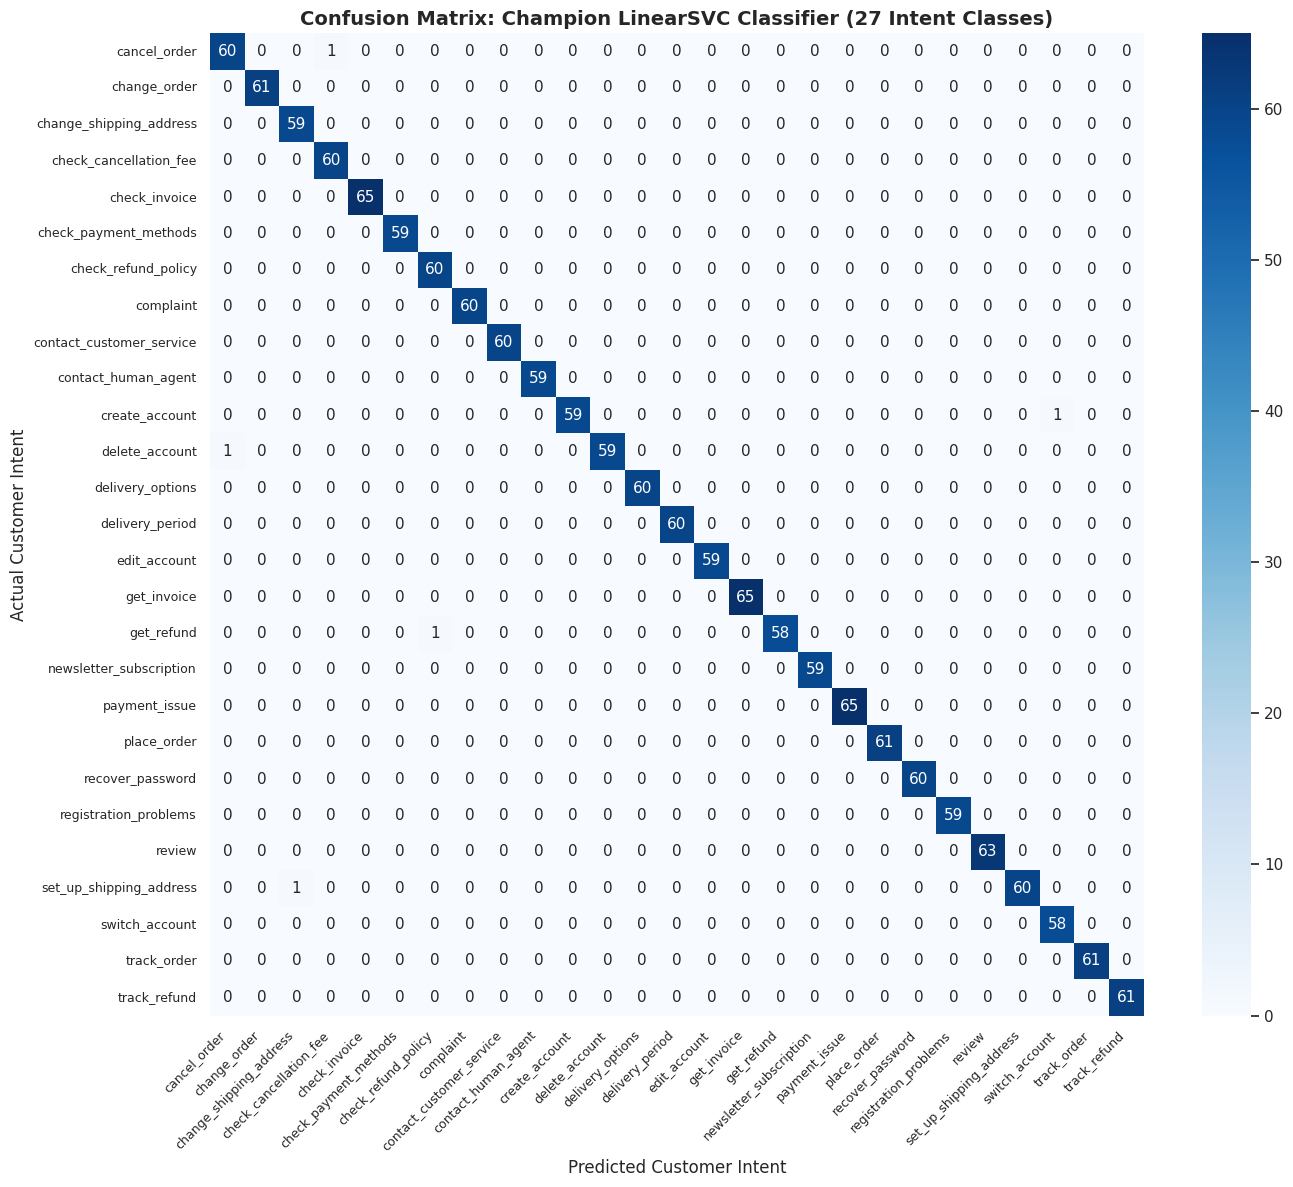

Total Test Misclassifications: 5 out of 1635 (0.31% error rate)

Raw Customer Utterance                                  | Actual Intent (y_true)    | Predicted Intent (y_pred)
--------------------------------------------------------------------------------------------------------------
order cancellation                                      | cancel_order              | check_cancellation_fee   
I do not know how I can ask for compensations           | get_refund                | check_refund_policy      
i need assistance cancelling an online acfcount         | delete_account            | cancel_order             
i need assistance to craete a new user account          | create_account            | switch_account           
invalid shipping address                                | set_up_shipping_address   | change_shipping_address  


In [10]:
# =============================================================================
# CELL 10: CONFUSION MATRIX HEATMAP & ERROR LOGGING
# =============================================================================
plt.figure(figsize=(14, 12))
cm = confusion_matrix(y_test, y_pred_champion, labels=champion_model.classes_)
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=champion_model.classes_,
    yticklabels=champion_model.classes_,
    cbar=True
)
plt.title('Confusion Matrix: Champion LinearSVC Classifier (27 Intent Classes)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Customer Intent', fontsize=12)
plt.ylabel('Actual Customer Intent', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

# Error Analysis: Isolating All 5 Misclassified Test Records
test_indices = y_test.index
pred_series = pd.Series(y_pred_champion, index=test_indices)
misclass_idx = test_indices[y_test != pred_series]

print(f"Total Test Misclassifications: {len(misclass_idx)} out of {len(y_test)} ({(len(misclass_idx)/len(y_test))*100:.2f}% error rate)\n")
print("{:<55} | {:<25} | {:<25}".format("Raw Customer Utterance", "Actual Intent (y_true)", "Predicted Intent (y_pred)"))
print("-" * 110)
for idx in misclass_idx:
    utt = df.loc[idx, 'utterance']
    true_lbl = y_test[idx]
    pred_lbl = pred_series[idx]
    print(f"{utt:<55} | {true_lbl:<25} | {pred_lbl:<25}")

In [11]:
# =============================================================================
# CELL 11: HIGH-LEVEL DEPARTMENTAL ROUTING BENCHMARK
# =============================================================================
y_cat = df['category']
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_cat, test_size=0.20, random_state=42, stratify=y_cat
)

cat_vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.95, sublinear_tf=True)
X_train_c_vec = cat_vectorizer.fit_transform(X_train_c)
X_test_c_vec = cat_vectorizer.transform(X_test_c)

svc_dept = LinearSVC(C=1.0, random_state=42, dual=False)
svc_dept.fit(X_train_c_vec, y_train_c)
y_pred_dept = svc_dept.predict(X_test_c_vec)

dept_acc = accuracy_score(y_test_c, y_pred_dept)
dept_f1 = f1_score(y_test_c, y_pred_dept, average='macro')

print("--- High-Level Departmental Domain Classification Results ---")
print(f"Domain Routing Accuracy: {dept_acc*100:.2f}%")
print(f"Domain Routing Macro F1-Score: {dept_f1:.4f}")
print("\nDepartmental Classification Report:")
print(classification_report(y_test_c, y_pred_dept, digits=4))

--- High-Level Departmental Domain Classification Results ---
Domain Routing Accuracy: 99.88%
Domain Routing Macro F1-Score: 0.9989

Departmental Classification Report:
                  precision    recall  f1-score   support

         ACCOUNT     0.9972    1.0000    0.9986       355
CANCELLATION_FEE     1.0000    1.0000    1.0000        59
         CONTACT     1.0000    1.0000    1.0000       119
        DELIVERY     0.9918    1.0000    0.9959       121
        FEEDBACK     1.0000    1.0000    1.0000       122
         INVOICE     1.0000    1.0000    1.0000       130
      NEWSLETTER     1.0000    1.0000    1.0000        59
           ORDER     1.0000    1.0000    1.0000       244
         PAYMENT     1.0000    1.0000    1.0000       124
          REFUND     1.0000    0.9945    0.9972       181
SHIPPING_ADDRESS     1.0000    0.9917    0.9959       121

        accuracy                         0.9988      1635
       macro avg     0.9990    0.9987    0.9989      1635
    weighted avg 

In [12]:
# =============================================================================
# CELL 12: DEPLOYABLE INFERENCE PIPELINE & LIVE TEST
# =============================================================================
# Encapsulate vectorization and modeling into a unified Pipeline object
routing_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.95, sublinear_tf=True)),
    ('clf', LinearSVC(C=1.0, random_state=42, dual=False))
])

# Fit on full normalized dataset for deployment readiness
routing_pipeline.fit(df['cleaned_text'], df['intent'])

# Live test sample queries
sample_inquiries = [
    "I was charged twice on my credit card for invoice #9482, please reverse it",
    "I want to cancel my active monthly membership right now",
    "My package has not arrived yet, where can I check the shipment status?",
    "I forgot my security credentials and need to reset my password",
    "Can I update my delivery address to a new apartment before it ships?",
    "How much does it cost if I terminate my service early?"
]

print("--- Real-Time Production Pipeline Dispatch Test ---")
print("{:<70} | {:<25}".format("Incoming Customer Transcript", "Predicted Routing Intent"))
print("-" * 100)
for query in sample_inquiries:
    clean_q = normalize_transcript(query)
    predicted_intent = routing_pipeline.predict([clean_q])[0]
    print(f"{query:<70} | {predicted_intent:<25}")

--- Real-Time Production Pipeline Dispatch Test ---
Incoming Customer Transcript                                           | Predicted Routing Intent 
----------------------------------------------------------------------------------------------------
I was charged twice on my credit card for invoice #9482, please reverse it | edit_account             
I want to cancel my active monthly membership right now                | cancel_order             
My package has not arrived yet, where can I check the shipment status? | track_refund             
I forgot my security credentials and need to reset my password         | recover_password         
Can I update my delivery address to a new apartment before it ships?   | change_shipping_address  
How much does it cost if I terminate my service early?                 | check_cancellation_fee   
